<a href="https://colab.research.google.com/github/jt7827/senior-thesis-code/blob/main/Thesis_Misinfo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import subprocess

repo_path = "./GNN-FakeNews"
if not os.path.exists(repo_path):
    subprocess.run(["git", "clone", "https://github.com/safe-graph/GNN-FakeNews.git", repo_path])

for root, dirs, files in os.walk(repo_path):
    level = root.replace(repo_path, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:15]:
            print("  " * (level + 1) + file)

!pip -q install torch-geometric

from torch_geometric.datasets import UPFD

def load_upfd(name, feature="profile", root="/content/data"):
    splits = {
        s: UPFD(root=root, name=name, feature=feature, split=s)
        for s in ["train", "val", "test"]
    }
    full = [g for s in ["train", "val", "test"] for g in splits[s]]
    return splits, full

pol_splits, pol_full = load_upfd("politifact")
gos_splits, gos_full = load_upfd("gossipcop")

for name, splits, full in [("PolitiFact", pol_splits, pol_full),
                           ("GossipCop", gos_splits, gos_full)]:
    print(name, {s: len(d) for s, d in splits.items()}, "total:", len(full))

fatal: destination path 'GNN-FakeNews' already exists and is not an empty directory.
GNN-FakeNews/
  LICENSE
  .gitignore
  README.md
  overview.png
  requirements.txt
  hyper_parameters.md
  utils/
    profile_feature.py
    twitter_crawler.py
    eval_helper.py
    data_loader.py
  data/
    gos_news_list.txt
    pol_id_twitter_mapping.pkl
    gos_id_time_mapping.pkl
    gos_id_twitter_mapping.pkl
    pol_id_time_mapping.pkl
    pol_news_list.txt
  gnn_model/
    bigcn.py
    gnn.py
    gnncl.py
    gcnfn.py
  .idea/
    .gitignore
  .git/
    config
    HEAD
    description
    index
    packed-refs
    hooks/
      pre-commit.sample
      applypatch-msg.sample
      update.sample
      sendemail-validate.sample
      fsmonitor-watchman.sample
      pre-rebase.sample
      commit-msg.sample
      push-to-checkout.sample
      pre-receive.sample
      post-update.sample
      prepare-commit-msg.sample
      pre-applypatch.sample
      pre-push.sample
      pre-merge-commit.sample
   

In [ ]:
#summary stats
import pandas as pd
import numpy as np

def summarize_upfd(dataset, name):
    graph_sizes = []
    edge_sizes = []
    labels = []

    for graph in dataset:
        graph_sizes.append(graph.num_nodes)
        edge_sizes.append(graph.num_edges)

        # UPFD labels: 0 = real, 1 = fake
        labels.append(int(graph.y.item()))

    sizes = pd.Series(graph_sizes, name="Nodes per graph")
    edges = pd.Series(edge_sizes, name="Edges per graph")
    labels = pd.Series(labels, name="Label")

    print(f"\n{'='*40}")
    print(name)
    print(f"{'='*40}")

    print("\nDataset size:", len(dataset))
    print("\nLabel counts:")
    print(labels.map({0: "Real", 1: "Fake"}).value_counts())

    print("\nNode statistics:")
    print(sizes.describe())

    print("\nEdge statistics:")
    print(edges.describe())

    print("\nTotal nodes:", sizes.sum())
    print("Total edges:", edges.sum())

    return pd.DataFrame({
        "nodes": sizes,
        "edges": edges,
        "label": labels.map({0: "Real", 1: "Fake"})
    })

pol_stats = summarize_upfd(pol_full, "PolitiFact")
gos_stats = summarize_upfd(gos_full, "GossipCop")


PolitiFact

Dataset size: 314

Label counts:
Label
Real    157
Fake    157
Name: count, dtype: int64

Node statistics:
count    314.000000
mean     130.745223
std      130.559665
min        3.000000
25%       26.000000
50%       78.500000
75%      216.750000
max      497.000000
Name: Nodes per graph, dtype: float64

Edge statistics:
count    314.000000
mean     129.745223
std      130.559665
min        2.000000
25%       25.000000
50%       77.500000
75%      215.750000
max      496.000000
Name: Edges per graph, dtype: float64

Total nodes: 41054
Total edges: 40740

GossipCop

Dataset size: 5464

Label counts:
Label
Real    2732
Fake    2732
Name: count, dtype: int64

Node statistics:
count    5464.000000
mean       57.515007
std        45.230782
min         3.000000
25%        19.000000
50%        49.000000
75%        84.000000
max       199.000000
Name: Nodes per graph, dtype: float64

Edge statistics:
count    5464.000000
mean       56.515007
std        45.230782
min         2.0000

In [ ]:
# generate features
"""Structural + profile feature extraction for UPFD retweet trees.

Works on one graph at a time from (edge_index, x). Edge direction is ignored:
the tree is rebuilt as undirected and rooted at `root` (node 0 by default).
Run `check_tree` on some graphs first to confirm that assumption.
"""
from collections import deque
import numpy as np
import pandas as pd


def _adjacency(edge_index, n):
    adj = [[] for _ in range(n)]
    for u, v in edge_index.T:
        adj[int(u)].append(int(v))
        adj[int(v)].append(int(u))
    return adj


def root_tree(edge_index, n, root=0):
    """BFS from root. Returns parent, depth, bfs_order (parent[root] = -1)."""
    adj = _adjacency(edge_index, n)
    parent = np.full(n, -2)          # -2 = unvisited
    depth = np.zeros(n, dtype=int)
    parent[root] = -1
    order, q = [], deque([root])
    while q:
        u = q.popleft()
        order.append(u)
        for v in adj[u]:
            if parent[v] == -2:
                parent[v] = u
                depth[v] = depth[u] + 1
                q.append(v)
    return parent, depth, np.array(order)


def check_tree(edge_index, n, root=0):
    """Sanity checks. Returns a dict you can eyeball / assert on."""
    parent, depth, order = root_tree(edge_index, n, root)
    src, dst = edge_index
    # An edge is "parent->child" if parent[dst] == src
    down = np.mean([parent[d] == s for s, d in zip(src, dst)])
    up = np.mean([parent[s] == d for s, d in zip(src, dst)])
    return {
        "n_nodes": n,
        "n_edges": edge_index.shape[1],
        "is_tree": edge_index.shape[1] == n - 1 and len(order) == n,
        "frac_edges_parent_to_child": down,
        "frac_edges_child_to_parent": up,
        "root_degree": int((parent == root).sum()),
    }


def structural_features(edge_index, n, root=0):
    parent, depth, order = root_tree(edge_index, n, root)
    assert len(order) == n, "graph not connected from root"

    # subtree sizes (reverse BFS order accumulates children into parents)
    size = np.ones(n, dtype=int)
    for v in order[::-1]:
        if parent[v] >= 0:
            size[parent[v]] += size[v]

    children = np.bincount(parent[parent >= 0], minlength=n)
    non_leaf = children > 0
    non_root = np.arange(n) != root

    level_counts = np.bincount(depth)          # includes root level (count 1)

    # structural virality = mean pairwise distance = Wiener index / C(n,2).
    # For a tree, Wiener index = sum over non-root v of size[v] * (n - size[v]).
    wiener = float((size[non_root] * (n - size[non_root])).sum())
    virality = wiener / (n * (n - 1) / 2)

    return {
        "size": n,
        "depth": int(depth.max()),
        "max_breadth": int(level_counts.max()),
        "branching_factor": float(children[non_leaf].mean()),
        "subtree_mean": float(size[non_root].mean()),
        "subtree_max": int(size[non_root].max()),
        "virality": virality,
        "frac_one_hop": float((parent == root).sum() / (n - 1)),
    }


def profile_features(edge_index, x, n, root=0):
    """Aggregate 10-d profile features two ways (prefix: all_ / root_)."""
    parent, _, _ = root_tree(edge_index, n, root)
    non_root = np.arange(n) != root
    direct = parent == root
    out = {}
    for j in range(x.shape[1]):
        out[f"prof{j}_all"] = float(x[non_root, j].mean())
        out[f"prof{j}_root"] = float(x[direct, j].mean())
    return out


def build_feature_table(split_dataset, split_name, root=0):
    rows = []
    for i, g in enumerate(split_dataset):
        ei = g.edge_index.numpy()
        x = g.x.numpy()
        n = g.num_nodes
        row = {"split": split_name, "idx": i, "label": int(g.y.item())}
        row.update(structural_features(ei, n, root))
        row.update(profile_features(ei, x, n, root))
        rows.append(row)
    return pd.DataFrame(rows)


def build_all(splits, root=0):
    """splits: dict like {'train': ds, 'val': ds, 'test': ds}."""
    return pd.concat(
        [build_feature_table(ds, name, root) for name, ds in splits.items()],
        ignore_index=True,
    )

In [ ]:
# 1. Verify tree structure and root assumption
for ds in [pol_splits["train"], gos_splits["train"]]:
    checks = pd.DataFrame([check_tree(g.edge_index.numpy(), g.num_nodes) for g in ds])
    print(checks.describe())
    print("all trees:", checks.is_tree.all())

# 2. Build features per split (test set built but not touched until comparison metric is fixed)
pol_feats = build_all(pol_splits)
gos_feats = build_all(gos_splits)

# 3. Descriptive stats, train only, by label
for name, df in [("PolitiFact", pol_feats), ("GossipCop", gos_feats)]:
    tr = df[df.split == "train"]
    print(name)
    print(tr.groupby("label")[["size","depth","max_breadth","branching_factor",
                               "subtree_mean","subtree_max","virality","frac_one_hop"]].describe().T)

          n_nodes     n_edges  frac_edges_parent_to_child  \
count   62.000000   62.000000                        62.0   
mean    97.935484   96.935484                         1.0   
std    113.094023  113.094023                         0.0   
min      4.000000    3.000000                         1.0   
25%     22.000000   21.000000                         1.0   
50%     51.000000   50.000000                         1.0   
75%    131.500000  130.500000                         1.0   
max    492.000000  491.000000                         1.0   

       frac_edges_child_to_parent  root_degree  
count                        62.0    62.000000  
mean                          0.0    48.612903  
std                           0.0    53.320360  
min                           0.0     1.000000  
25%                           0.0    13.250000  
50%                           0.0    25.000000  
75%                           0.0    69.000000  
max                           0.0   285.000000  
all trees

In [ ]:
cols = ["size","depth","max_breadth","branching_factor",
        "subtree_mean","subtree_max","virality","frac_one_hop"]

for name, df in [("PolitiFact", pol_feats), ("GossipCop", gos_feats)]:
    tr = df[df.split == "train"]
    print(name)
    print(tr.groupby("label")[cols].median().T.round(3))

# size-only baseline: fit on train, score on val (val only, test stays untouched)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score
import numpy as np

for name, df in [("PolitiFact", pol_feats), ("GossipCop", gos_feats)]:
    tr, va = df[df.split=="train"], df[df.split=="val"]
    m = LogisticRegression(max_iter=1000).fit(np.log1p(tr[["size"]]), tr.label)
    p = m.predict_proba(np.log1p(va[["size"]]))[:, 1]
    print(name, "val AUC:", round(roc_auc_score(va.label, p), 3),
          "val acc:", round(accuracy_score(va.label, p > 0.5), 3))

PolitiFact
label                  0       1
size              51.000  46.500
depth              3.000   3.500
max_breadth       33.000  28.500
branching_factor   5.750   5.261
subtree_mean       1.518   1.496
subtree_max        8.500  10.500
virality           2.684   2.781
frac_one_hop       0.609   0.633
GossipCop
label                  0       1
size              73.000  21.000
depth              2.000   2.000
max_breadth       62.000  15.000
branching_factor  21.333   5.500
subtree_mean       1.067   1.222
subtree_max        3.000   3.000
virality           2.074   2.154
frac_one_hop       0.938   0.789
PolitiFact val AUC: 0.656 val acc: 0.419
GossipCop val AUC: 0.799 val acc: 0.756


In [ ]:
"""Attach per-node timestamps to UPFD graphs.

Assumptions (from the GNN-FakeNews README and PyG's UPFD loader; the
`validate` function checks them on the real data rather than trusting them):
  * data/{pol,gos}_id_time_mapping.pkl maps GLOBAL node id -> UNIX timestamp
  * global node ids are contiguous per graph, in the order given by
    raw/node_graph_id.npy
  * PyG's split dataset i is full graph raw/{split}_idx.npy[i]
  * the news (root) node has no timestamp
"""
import pickle
import numpy as np

SHORT = {"politifact": "pol", "gossipcop": "gos"}


def _to_float(v):
    """Missing timestamps appear as '' (or None) in the pickles -> NaN."""
    if v is None or (isinstance(v, str) and v.strip() == ""):
        return np.nan
    return float(v)


def load_time_map(name, repo_path="/content/GNN-FakeNews"):
    path = f"{repo_path}/data/{SHORT[name]}_id_time_mapping.pkl"
    with open(path, "rb") as f:
        return pickle.load(f)


def inspect_time_map(tm, n_total_nodes=None):
    """Print what the pickle actually looks like before we rely on it."""
    keys = list(tm.keys())
    print("type:", type(tm).__name__, "| entries:", len(tm))
    print("key type:", type(keys[0]).__name__, "| sample keys:", keys[:5])
    print("sample values:", [tm[k] for k in keys[:5]])
    try:
        ik = np.array([int(k) for k in keys])
        print("key range:", ik.min(), "to", ik.max())
        if n_total_nodes is not None:
            print("total nodes in raw data:", n_total_nodes,
                  "| keys outside [0, N):", int(((ik < 0) | (ik >= n_total_nodes)).sum()))
    except (ValueError, TypeError):
        print("keys are not integer-like; mapping format differs from assumption")
    allvals = np.array([_to_float(v) for v in tm.values()])
    vals = allvals[~np.isnan(allvals)]
    print("entries with no timestamp ('' or None):", int(np.isnan(allvals).sum()))
    print("value range:", vals.min(), "to", vals.max(),
          "(UNIX seconds are ~1.4e9 to 1.7e9; ~1e12+ would mean milliseconds)")


def load_raw_layout(name, raw_root="/content/data"):
    raw = f"{raw_root}/{name}/raw"
    node_graph_id = np.load(f"{raw}/node_graph_id.npy")
    labels = np.load(f"{raw}/graph_labels.npy")
    _, labels = np.unique(labels, return_inverse=True)   # same remap PyG does
    node_slice = np.concatenate([[0], np.cumsum(np.bincount(node_graph_id))])
    split_idx = {s: np.load(f"{raw}/{s}_idx.npy") for s in ["train", "val", "test"]}
    return node_slice, labels, split_idx


def global_time_array(tm, n_total_nodes):
    t = np.full(n_total_nodes, np.nan)
    for k, v in tm.items():
        k = int(k)
        if 0 <= k < n_total_nodes:
            t[k] = _to_float(v)
    return t


def graph_times(name, repo_path="/content/GNN-FakeNews", raw_root="/content/data"):
    """Returns {split: [np.array of timestamps per graph, local node order]}.

    Entry i of each list lines up with PyG's UPFD(name, split=split)[i];
    missing timestamps (e.g. the root) are NaN.
    """
    node_slice, labels, split_idx = load_raw_layout(name, raw_root)
    tm = load_time_map(name, repo_path)
    t = global_time_array(tm, int(node_slice[-1]))
    out = {}
    for s, idx in split_idx.items():
        out[s] = [t[node_slice[g]:node_slice[g + 1]] for g in idx]
    return out


def validate(name, splits, times, raw_root="/content/data"):
    """splits: {'train': UPFD ds, ...}; times: output of graph_times."""
    _, labels, split_idx = load_raw_layout(name, raw_root)
    size_bad = label_bad = 0
    n_nodes = n_have = 0
    missing_local = []
    viol_edges = checked_edges = viol_graphs = 0
    for s, ds in splits.items():
        for i, g in enumerate(ds):
            ts = times[s][i]
            if len(ts) != g.num_nodes:
                size_bad += 1
                continue
            if int(labels[split_idx[s][i]]) != int(np.asarray(g.y).reshape(-1)[0]):
                label_bad += 1
            have = ~np.isnan(ts)
            n_nodes += len(ts)
            n_have += have.sum()
            missing_local += list(np.where(~have)[0])
            ei = np.asarray(g.edge_index)
            p, c = ei[0], ei[1]
            ok = have[p] & have[c]                 # skips root edges if root is NaN
            checked_edges += int(ok.sum())
            v = int((ts[c][ok] < ts[p][ok]).sum()) # child earlier than parent
            viol_edges += v
            viol_graphs += v > 0
    miss = np.array(missing_local)
    print(f"[{name}] graphs with node-count mismatch: {size_bad}")
    print(f"[{name}] graphs with label mismatch:      {label_bad}")
    print(f"[{name}] nodes with a timestamp:          {n_have}/{n_nodes} "
          f"({n_have / max(n_nodes, 1):.1%})")
    if len(miss):
        print(f"[{name}] missing nodes that are local id 0 (root): "
              f"{(miss == 0).mean():.1%} of all missing")
    print(f"[{name}] child-before-parent edges: {viol_edges}/{checked_edges} "
          f"({viol_edges / max(checked_edges, 1):.2%}); graphs affected: {viol_graphs}")
    return dict(size_bad=size_bad, label_bad=label_bad, viol_edges=viol_edges,
                checked_edges=checked_edges)

In [ ]:

# 1. Look at the raw pickle first (before trusting the format)
for name in ["politifact", "gossipcop"]:
    node_slice, _, _ = load_raw_layout(name)
    print(name)
    inspect_time_map(load_time_map(name), n_total_nodes=int(node_slice[-1]))

# 2. Build per-graph timestamps, aligned to your existing PyG datasets
pol_times = graph_times("politifact")
gos_times = graph_times("gossipcop")

# 3. Validate the alignment
validate("politifact", pol_splits, pol_times)
validate("gossipcop", gos_splits, gos_times)

politifact
type: dict | entries: 41054
key type: int | sample keys: [0, 1, 2, 3, 4]
sample values: ['', 1231344102, 1231344109, 1231869022, 1232841677]
key range: 0 to 41053
total nodes in raw data: 41054 | keys outside [0, N): 0
entries with no timestamp ('' or None): 314
value range: 1186670987.0 to 1544980039.0 (UNIX seconds are ~1.4e9 to 1.7e9; ~1e12+ would mean milliseconds)
gossipcop
type: dict | entries: 314262
key type: int | sample keys: [0, 1, 2, 3, 4]
sample values: ['', 1528805290, 1528805421, 1528805584, 1528805797]
key range: 0 to 314261
total nodes in raw data: 314262 | keys outside [0, N): 0
entries with no timestamp ('' or None): 5464
value range: 1210621281.0 to 1545059104.0 (UNIX seconds are ~1.4e9 to 1.7e9; ~1e12+ would mean milliseconds)
[politifact] graphs with node-count mismatch: 0
[politifact] graphs with label mismatch:      0
[politifact] nodes with a timestamp:          40740/41054 (99.2%)
[politifact] missing nodes that are local id 0 (root): 100.0% of all 

{'size_bad': 0, 'label_bad': 0, 'viol_edges': 0, 'checked_edges': 71980}

In [ ]:
import numpy as np, pandas as pd

def span_table(times, splits):
    rows = []
    for s in ["train"]:                      # train only, as with the other descriptives
        for i, ts in enumerate(times[s]):
            t = ts[~np.isnan(ts)]
            rows.append({"label": int(splits[s][i].y), "n": len(t),
                         "span_hours": (t.max() - t.min()) / 3600})
    return pd.DataFrame(rows)

for name, times, splits in [("PolitiFact", pol_times, pol_splits),
                            ("GossipCop", gos_times, gos_splits)]:
    print(name)
    print(span_table(times, splits).groupby("label").span_hours.describe().round(1))

PolitiFact
       count     mean      std   min    25%      50%      75%      max
label                                                                 
0       36.0  31986.6  34805.8  10.5  459.5  12142.4  61724.2  89105.5
1       26.0   5632.6  11906.6  46.2  235.7   1355.1   4640.4  56848.9
GossipCop
       count    mean      std  min   25%    50%     75%      max
label                                                           
0      557.0  1438.5   4318.2  0.2  50.0  170.0   739.0  54023.6
1      535.0  7387.0  15234.6  0.8  63.7  601.4  6566.7  82260.6


In [ ]:
from datetime import datetime, timezone

"""Temporal (propagation speed) + extra structural features, and one combined table.

Paste into a notebook cell AFTER your feature-extraction and timestamp cells
(it reuses root_tree, structural_features, profile_features and graph_times).

Time origin: the root (news) node has no timestamp, so every cascade's clock
starts at its EARLIEST non-root tweet (t0). All times are hours after t0.
"""

HOUR = 3600.0

STRUCT_COLS = ["size", "depth", "max_breadth", "branching_factor", "subtree_mean",
               "subtree_max", "virality", "frac_one_hop",
               "root_degree", "frac_leaves", "mean_depth", "max_breadth_frac",
               "subtree_max_frac"]
SPEED_COLS = ["span_h", "avgIntertweet_T", "medianIntertweet_T", "maxIntertweet_T", "stdIntertweet_T",
              "burstiness",
              "t25percent", "t50percent", "t75percent", "t90percent",
              "t25_frac", "t50_frac", "t75_frac", "t90_frac",
              "n_1h", "n_6h", "n_24h", "frac_1h", "frac_6h", "frac_24h",
              "peak_hour_frac", "lag_mean_h", "lag_median_h", "t50perNorm", "meanIntertweetNorm"]


def check_absolute(times, name=""):
    """Are timestamps absolute UNIX times (not offsets from the root)?"""
    firsts = []
    for lst in times.values():
        for ts in lst:
            t = ts[~np.isnan(ts)]
            if len(t):
                firsts.append(t.min())
    f = np.array(firsts)
    fmt = lambda v: datetime.fromtimestamp(v, tz=timezone.utc).strftime("%Y-%m-%d")
    print(f"[{name}] graphs: {len(f)}")
    print(f"[{name}] earliest tweet per graph: min {fmt(f.min())}, "
          f"median {fmt(np.median(f))}, max {fmt(f.max())}")
    print(f"[{name}] graphs whose earliest value is < 1e8 (would look like an offset): "
          f"{(f < 1e8).mean():.1%}")
    print(f"[{name}] spread of earliest times across graphs: {f.std() / 86400:.0f} days "
          f"(offsets from a root would all sit near 0)")


def extra_structural(parent, depth, order, n, root=0):
    size = np.ones(n, dtype=int)
    for v in order[::-1]:
        if parent[v] >= 0:
            size[parent[v]] += size[v]
    children = np.bincount(parent[parent >= 0], minlength=n)
    nr = np.arange(n) != root
    return {
        "root_degree": int(children[root]),
        "frac_leaves": float((children[nr] == 0).mean()),
        "mean_depth": float(depth[nr].mean()),
        "max_breadth_frac": float(np.bincount(depth).max() / n),
        "subtree_max_frac": float(size[nr].max() / (n - 1)),
    }


def temporal_features(ts, parent, root=0):
    """ts: timestamps (seconds) in local node order, NaN for root/missing."""
    n = len(ts)
    out = dict.fromkeys(SPEED_COLS, np.nan)
    t = ts[np.arange(n) != root]
    t = np.sort(t[~np.isnan(t)])
    k = len(t)
    if k == 0:
      return out

    if k == 1:
      out["span_h"] = 0.0
      for q in (25, 50, 75, 90):
        out[f"t{q}percent"] = 0.0
        out[f"t{q}_frac"] = 0.0
      for w in (1, 6, 24):
        out[f"n_{w}h"] = 1
        out[f"frac_{w}h"] = 1.0
      out["peak_hour_frac"] = 1.0
      return out

    rel = (t - t[0]) / HOUR                 # hours after the first retweet
    span = rel[-1]
    gaps = np.diff(rel)
    gm, gs = gaps.mean(), gaps.std()
    out.update(span_h=span, avgIntertweet_T=gm, medianIntertweet_T=float(np.median(gaps)),
               maxIntertweet_T=gaps.max(), stdIntertweet_T=gs,
               burstiness=(gs - gm) / (gs + gm) if gs + gm > 0 else 0.0)
    for q in (25, 50, 75, 90):              # time until q% of retweets have occurred
        idx = max(int(np.ceil(q / 100 * k)) - 1, 0)
        out[f"t{q}percent"] = rel[idx]
        out[f"t{q}_frac"] = rel[idx] / span if span > 0 else 0.0
    for w in (1, 6, 24):                    # early activity
        cnt = int((rel <= w).sum())
        out[f"n_{w}h"] = cnt
        out[f"frac_{w}h"] = cnt / k
    out["peak_hour_frac"] = np.bincount(np.floor(rel).astype(int)).max() / k
    # lag between a retweeter and the (non-root) account it was attached to
    child = np.where((np.arange(n) != root) & (parent >= 0) & (parent != root))[0]
    if len(child):
        lag = (ts[child] - ts[parent[child]]) / HOUR
        lag = lag[~np.isnan(lag)]
        if len(lag):
            out["lag_mean_h"] = float(lag.mean())
            out["lag_median_h"] = float(np.median(lag))
    return out


def build_full_table(splits, times, root=0):
    """splits: {'train': ds, ...}; times: output of graph_times(name)."""
    rows = []
    for s, ds in splits.items():
        for i, g in enumerate(ds):
            ei, x, n = g.edge_index.numpy(), g.x.numpy(), g.num_nodes
            parent, depth, order = root_tree(ei, n, root)
            row = {"split": s, "idx": i, "label": int(g.y.item())}
            row.update(structural_features(ei, n, root))
            row.update(extra_structural(parent, depth, order, n, root))
            row.update(profile_features(ei, x, n, root))
            row.update(temporal_features(times[s][i], parent, root))
            row.update(profile_features_normalized(ei, x, n, root))
            row.update(normalized_temporal_features(times[s][i], depth, root))
            rows.append(row)
    return pd.DataFrame(rows)


def feature_groups(df):
    prof = [c for c in df.columns if c.startswith("prof")]
    return {"size": ["size"],
            "structure": [c for c in STRUCT_COLS if c != "size"],  # size is its own group
            "speed": SPEED_COLS,
            "profile": prof}


def default_log_cols(cols):
    """Heavy-tailed columns that get log1p (parameter-free, so no leakage)."""
    skew = {"size", "max_breadth", "branching_factor", "subtree_mean",
            "subtree_max", "root_degree", "avgIntertweet_T", "medianIntertweet_T", "maxIntertweet_T",
            "stdIntertweet_T", "t25percent", "t50percent", "t75percent", "t90percent",
            "t50perNorm", "meanIntertweetNorm"}
    out = []
    for c in cols:
        is_prof_count = c.startswith("prof") and int(c[4]) in (2, 3, 4, 5, 6)
        if c in skew or c.endswith("_h") or c.startswith("n_") or is_prof_count:
            out.append(c)
    return out


def make_xy(df, cols, log_cols=(), ref=None):
    """Log-transform, impute NaNs with TRAIN medians, add missing-indicators.

    Call on the train rows first (ref=None), then pass the returned ref when
    transforming val/test so nothing is learned from them.
    """
    X = df[cols].astype(float).copy()

    for c in log_cols:
        if c in X:
            X[c] = np.log1p(X[c].clip(lower=0))

    if ref is None:
        # Remove columns that have no observed training values (fix NaN issue, some features excluded for those that dont have them)
        keep_cols = X.columns[X.notna().any()].tolist()
        X = X[keep_cols]

        ref = {
            "cols": keep_cols,
            "median": X.median(),
            "miss_cols": [c for c in X if X[c].isna().any()]
        }
    else:
        # Use exactly the same columns and medians as training
        X = X[ref["cols"]]

    for c in ref["miss_cols"]:
        X[c + "_missing"] = X[c].isna().astype(float)

    X = X.fillna(ref["median"])

    return X, df["label"].values, ref


In [ ]:
def normalized_mean_aggregate(values, depth, root=0):
    """
    Calculate the mean of per-level means across all non-root levels.
    """
    values = np.asarray(values, dtype=float)
    non_root = np.arange(len(values)) != root

    level_means = []

    for d in np.unique(depth[non_root]):
        mask = (depth == d) & non_root & np.isfinite(values)

        if mask.any():
            level_means.append(values[mask].mean())

    return float(np.mean(level_means)) if level_means else np.nan

def profile_features_normalized(edge_index, x, n, root=0):
    parent, depth, _ = root_tree(edge_index, n, root)

    non_root = np.arange(n) != root
    direct = parent == root

    out = {}

    for j in range(x.shape[1]):
        out[f"prof{j}_all_level"] = normalized_mean_aggregate(
            x[:, j], depth, root
        )

        out[f"prof{j}_root"] = (
            float(x[direct, j].mean()) if direct.any() else np.nan
        )

    return out

def normalized_temporal_features(ts, depth, root=0):
    """
    Calculate level-normalized t50 and mean inter-tweet gaps.
    All times are measured in hours after the first retweet.
    """
    n = len(ts)
    non_root = np.arange(n) != root

    valid = non_root & np.isfinite(ts)

    if not valid.any():
        return {
            "t50perNorm": np.nan,
            "meanIntertweetNorm": np.nan
        }

    t0 = np.min(ts[valid])
    rel = (ts - t0) / HOUR

    level_t50 = []
    level_gaps = []

    for d in np.unique(depth[non_root]):
        mask = (depth == d) & valid
        level_times = np.sort(rel[mask])

        if len(level_times):
            # Time until 50% of this level has appeared
            idx = max(int(np.ceil(0.50 * len(level_times))) - 1, 0)
            level_t50.append(level_times[idx])

        if len(level_times) >= 2:
            gaps = np.diff(level_times)
            level_gaps.append(gaps.mean())

    return {
        "t50perNorm": (
            float(np.mean(level_t50)) if level_t50 else np.nan
        ),
        "meanIntertweetNorm": (
            float(np.mean(level_gaps)) if level_gaps else np.nan
        )
    }



In [ ]:
# check: absolute times, not offsets from the root
check_absolute(pol_times, "PolitiFact")
check_absolute(gos_times, "GossipCop")

# Full feature tables (train/val/test; test stays untouched until you're ready)
pol_all = build_full_table(pol_splits, pol_times)
gos_all = build_full_table(gos_splits, gos_times)
print(pol_all.shape, gos_all.shape)
print(pol_all[SPEED_COLS].isna().mean().round(3))   # which features have gaps?

[PolitiFact] graphs: 314
[PolitiFact] earliest tweet per graph: min 2007-08-09, median 2016-09-02, max 2018-11-18
[PolitiFact] graphs whose earliest value is < 1e8 (would look like an offset): 0.0%
[PolitiFact] spread of earliest times across graphs: 1238 days (offsets from a root would all sit near 0)
[GossipCop] graphs: 5464
[GossipCop] earliest tweet per graph: min 2008-05-12, median 2017-10-26, max 2018-09-01
[GossipCop] graphs whose earliest value is < 1e8 (would look like an offset): 0.0%
[GossipCop] spread of earliest times across graphs: 536 days (offsets from a root would all sit near 0)
(314, 71) (5464, 71)
span_h                0.000
avgIntertweet_T       0.000
medianIntertweet_T    0.000
maxIntertweet_T       0.000
stdIntertweet_T       0.000
burstiness            0.000
t25percent            0.000
t50percent            0.000
t75percent            0.000
t90percent            0.000
t25_frac              0.000
t50_frac              0.000
t75_frac              0.000
t90_frac   

In [ ]:
print([c for c in pol_all.columns if "level" in c])
print([c for c in gos_all.columns if "level" in c])

['prof0_all_level', 'prof1_all_level', 'prof2_all_level', 'prof3_all_level', 'prof4_all_level', 'prof5_all_level', 'prof6_all_level', 'prof7_all_level', 'prof8_all_level', 'prof9_all_level']
['prof0_all_level', 'prof1_all_level', 'prof2_all_level', 'prof3_all_level', 'prof4_all_level', 'prof5_all_level', 'prof6_all_level', 'prof7_all_level', 'prof8_all_level', 'prof9_all_level']


In [ ]:
print(pol_all.shape)
print(gos_all.shape)
print(pol_all.head())

(314, 71)
(5464, 71)
   split  idx  label  size  depth  max_breadth  branching_factor  \
0  train    0      0    72      3           43         11.833333   
1  train    1      1    32      5           13          2.583333   
2  train    2      0   312      7          161          5.098361   
3  train    3      0   271      7          112          4.426230   
4  train    4      1    34      3           21          8.250000   

   subtree_mean  subtree_max  virality  ...  prof0_all_level  prof1_all_level  \
0      1.633803           23  2.931142  ...         0.081826         0.273902   
1      2.129032           11  3.681452  ...         0.000000         0.094872   
2      2.106109          106  3.871733  ...         0.014938         0.377458   
3      2.562963          123  4.551866  ...         0.028525         0.437457   
4      1.393939           10  2.520499  ...         0.000000         0.184704   

   prof2_all_level  prof3_all_level  prof4_all_level  prof5_all_level  \
0         

In [ ]:
print(gos_all.head())

   split  idx  label  size  depth  max_breadth  branching_factor  \
0  train    0      0    76      3           72         18.750000   
1  train    1      1   125      5           61          4.275862   
2  train    2      1     6      2            3          2.500000   
3  train    3      0    56      2           54         27.500000   
4  train    4      0    90      3           72         22.250000   

   subtree_mean  subtree_max  virality  ...  prof0_all_level  prof1_all_level  \
0      1.053333            3  2.075439  ...         0.009259         0.217593   
1      1.935484           53  3.445161  ...         0.005263         0.289654   
2      1.400000            3  1.933333  ...         0.750000         1.000000   
3      1.018182            2  1.998701  ...         0.000000         0.555556   
4      1.202247           17  2.308864  ...         0.004630         0.523148   

   prof2_all_level  prof3_all_level  prof4_all_level  prof5_all_level  \
0         0.002149         0.00

In [ ]:
level_cols = [c for c in pol_all.columns if "level" in c]

print(pol_all[level_cols].isna().mean().round(3))
print(gos_all[level_cols].isna().mean().round(3))

prof0_all_level    0.0
prof1_all_level    0.0
prof2_all_level    0.0
prof3_all_level    0.0
prof4_all_level    0.0
prof5_all_level    0.0
prof6_all_level    0.0
prof7_all_level    0.0
prof8_all_level    0.0
prof9_all_level    0.0
dtype: float64
prof0_all_level    0.0
prof1_all_level    0.0
prof2_all_level    0.0
prof3_all_level    0.0
prof4_all_level    0.0
prof5_all_level    0.0
prof6_all_level    0.0
prof7_all_level    0.0
prof8_all_level    0.0
prof9_all_level    0.0
dtype: float64


Now code regression model using features and look at results on training (nothing on all/validation/test until i decide on a comparison metric)

In [ ]:
"""Logistic / Lasso fits on TRAIN rows only, driven by a feature list.

Paste into a notebook cell after your feature cells (uses feature_groups,
make_xy and default_log_cols from your notebook).
"""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score


def feature_sets(df):
    g = feature_groups(df)
    struct_all = g["structure"] + g["speed"]      # "structure" = static structure + speed
    return {
        "size":           g["size"],
        "profile":        g["profile"],
        "structure":      struct_all,
        "profile+size":   g["profile"] + g["size"],
        "structure+size": struct_all + g["size"],
        "all":            g["size"] + struct_all + g["profile"],
    }


def fit_logistic_train(df, name, cols, penalty="l2", C=1.0, tune_C=False, seed=0):
    """Fit on TRAIN rows only. penalty='l1' is the Lasso. tune_C=True picks C by
    repeated CV within the training rows (log-loss); validation/test are untouched."""
    train_df = df[df["split"] == "train"]
    X, y, prep_ref = make_xy(train_df, cols, log_cols=default_log_cols(cols))

    if tune_C:
        cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed)
        clf = LogisticRegressionCV(Cs=np.logspace(-2, 1, 20), cv=cv, penalty=penalty,
                                   solver="liblinear", scoring="neg_log_loss", max_iter=5000)
    else:
        clf = LogisticRegression(penalty=penalty, solver="liblinear", C=C, max_iter=5000)

    model = make_pipeline(StandardScaler(), clf)
    model.fit(X, y)

    names = list(X.columns)
    coefs = pd.Series(model[-1].coef_[0], index=names)
    out = {"model": model, "prep_ref": prep_ref, "cols": cols, "coefs": coefs,
           "train_acc": accuracy_score(y, model.predict(X)),
           "n_nonzero": int((coefs != 0).sum()), "n_features": len(names)}
    if tune_C:
        sc = next(iter(clf.scores_.values())).mean(axis=0)
        out["C"] = float(clf.C_[0])
        out["cv_logloss"] = float(-sc.max())
    msg = (f"{name}: {len(names)} features, {out['n_nonzero']} nonzero, "
           f"train acc {out['train_acc']:.3f}")
    if tune_C:
        msg += f", C={out['C']:.3g}, CV log-loss {out['cv_logloss']:.3f}"
    print(msg)
    return out


def run_all_sets(df, name, penalty="l2", **kw):
    return {s: fit_logistic_train(df, f"{name}/{s}", cols, penalty=penalty, **kw)
            for s, cols in feature_sets(df).items()}



In [ ]:
# one set
r = fit_logistic_train(pol_all, "PolitiFact/all", feature_sets(pol_all)["all"],
                       penalty="l1", tune_C=True)

# all six sets
pol_res = run_all_sets(pol_all, "PolitiFact", penalty="l1", tune_C=True)
gos_res = run_all_sets(gos_all, "GossipCop",  penalty="l2", tune_C=True)

# coefficients for one fit, largest first
print(pol_res["all"]["coefs"].abs().sort_values(ascending=False).head(15))

PolitiFact/all: 68 features, 13 nonzero, train acc 0.935, C=0.379, CV log-loss 0.502
PolitiFact/size: 1 features, 0 nonzero, train acc 0.581, C=0.546, CV log-loss 0.685
PolitiFact/profile: 30 features, 10 nonzero, train acc 0.903, C=0.785, CV log-loss 0.485
PolitiFact/structure: 37 features, 8 nonzero, train acc 0.790, C=0.546, CV log-loss 0.664
PolitiFact/profile+size: 31 features, 10 nonzero, train acc 0.903, C=0.785, CV log-loss 0.486
PolitiFact/structure+size: 38 features, 8 nonzero, train acc 0.790, C=0.546, CV log-loss 0.664
PolitiFact/all: 68 features, 14 nonzero, train acc 0.935, C=0.379, CV log-loss 0.502
GossipCop/size: 1 features, 1 nonzero, train acc 0.759, C=0.785, CV log-loss 0.533
GossipCop/profile: 30 features, 30 nonzero, train acc 0.907, C=0.546, CV log-loss 0.284
GossipCop/structure: 38 features, 38 nonzero, train acc 0.898, C=0.127, CV log-loss 0.292
GossipCop/profile+size: 31 features, 31 nonzero, train acc 0.923, C=0.546, CV log-loss 0.252
GossipCop/structure+size

In [ ]:
"""
Purpose (matches your plan): (1) does a random forest beat the logistic model on
the same feature set? (nonlinearity/interaction check); (2) which features and
feature GROUPS matter, measured by how much held-out log-loss gets worse when
they are shuffled.
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import log_loss


def _rf(seed, n_estimators=300, **kw):
    return RandomForestClassifier(n_estimators=n_estimators, n_jobs=-1,
                                  random_state=seed, **kw)


def _group_of(columns, df):
    lookup = {}
    for gname, cs in feature_groups(df).items():
        for c in cs:
            lookup[c] = gname
    # a "_missing" flag belongs to the group of the column it flags
    return {c: lookup.get(c.replace("_missing", ""), "other") for c in columns}


def _perm_increase(model, Xv, yv, col_lists, n_repeats, rng):
    """Increase in held-out log-loss when each column set is shuffled jointly."""
    base = log_loss(yv, model.predict_proba(Xv), labels=[0, 1])
    out = {}
    for key, cols in col_lists.items():
        incr = []
        for _ in range(n_repeats):
            Xp = Xv.copy()
            Xp[cols] = Xv[cols].to_numpy()[rng.permutation(len(Xv))]
            incr.append(log_loss(yv, model.predict_proba(Xp), labels=[0, 1]) - base)
        out[key] = float(np.mean(incr))
    return out


def rf_importance(df, name, cols, seed=0, n_splits=5, n_repeats=3,
                  min_leaf_grid=(1, 3, 5, 10), perm_repeats=3, importance_repeats=2):
    """CV log-loss for the random forest + out-of-fold permutation importance.

    CV splits match the logistic fits (same seed / splits / repeats), so the
    cv_logloss values are directly comparable with fit_logistic_train(tune_C=True).
    """
    train_df = df[df["split"] == "train"]
    X, y, _ = make_xy(train_df, cols)              # no log transform: trees don't need it
    X = X.reset_index(drop=True)

    # 1. pick min_samples_leaf by CV log-loss (same folds as the logistic CV)
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    scores = {}
    for leaf in min_leaf_grid:
        ll = []
        for tr, va in cv.split(X, y):
            m = _rf(seed, min_samples_leaf=leaf).fit(X.iloc[tr], y[tr])
            ll.append(log_loss(y[va], m.predict_proba(X.iloc[va]), labels=[0, 1]))
        scores[leaf] = float(np.mean(ll))
    best = min(scores, key=scores.get)

    # 2. out-of-fold permutation importance with the chosen setting
    groups = _group_of(X.columns, df)
    feat_lists = {c: [c] for c in X.columns}
    grp_lists = {}
    for c, g in groups.items():
        grp_lists.setdefault(g, []).append(c)
    rng = np.random.default_rng(seed)
    cv_imp = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=importance_repeats,
                                     random_state=seed)
    feat_rows, grp_rows = [], []
    for tr, va in cv_imp.split(X, y):
        m = _rf(seed, min_samples_leaf=best).fit(X.iloc[tr], y[tr])
        m.n_jobs = 1                                # faster for many small predict calls
        feat_rows.append(_perm_increase(m, X.iloc[va], y[va], feat_lists, perm_repeats, rng))
        grp_rows.append(_perm_increase(m, X.iloc[va], y[va], grp_lists, perm_repeats, rng))

    fi = pd.DataFrame(feat_rows)
    feat = pd.DataFrame({"importance": fi.mean(), "sd": fi.std(),
                         "frac_folds_positive": (fi > 0).mean()})
    feat = feat.sort_values("importance", ascending=False)
    gi = pd.DataFrame(grp_rows)
    grp = pd.DataFrame({"importance": gi.mean(), "sd": gi.std(),
                        "frac_folds_positive": (gi > 0).mean()})
    grp = grp.sort_values("importance", ascending=False)

    print(f"{name}: {X.shape[1]} features, best min_samples_leaf={best}, "
          f"CV log-loss {scores[best]:.3f}")
    return {"best_leaf": best, "leaf_cv_logloss": scores, "cv_logloss": scores[best],
            "feature_importance": feat, "group_importance": grp}


def run_rf_all_sets(df, name, **kw):
    return {s: rf_importance(df, f"{name}/{s}", cols, **kw)
            for s, cols in feature_sets(df).items()}


def compare_to_logistic(log_res, rf_res):
    """Side-by-side CV log-loss (lower is better) on identical folds."""
    return pd.DataFrame({
        "logistic": {s: r["cv_logloss"] for s, r in log_res.items()},
        "random_forest": {s: r["cv_logloss"] for s, r in rf_res.items()},
    }).assign(rf_minus_logistic=lambda d: d["random_forest"] - d["logistic"]).round(3)

In [ ]:
pol_rf = run_rf_all_sets(pol_all, "PolitiFact")
gos_rf = run_rf_all_sets(gos_all, "GossipCop")

# nonlinearity check: needs pol_res / gos_res from run_all_sets(..., tune_C=True)
print(compare_to_logistic(pol_res, pol_rf))
print(compare_to_logistic(gos_res, gos_rf))

# rankings for one set
print(pol_rf["all"]["group_importance"])
print(pol_rf["all"]["feature_importance"].head(15))

PolitiFact/size: 1 features, best min_samples_leaf=10, CV log-loss 0.710
PolitiFact/profile: 30 features, best min_samples_leaf=1, CV log-loss 0.406
PolitiFact/structure: 37 features, best min_samples_leaf=1, CV log-loss 0.556
PolitiFact/profile+size: 31 features, best min_samples_leaf=1, CV log-loss 0.400
PolitiFact/structure+size: 38 features, best min_samples_leaf=1, CV log-loss 0.561
PolitiFact/all: 68 features, best min_samples_leaf=1, CV log-loss 0.360
GossipCop/size: 1 features, best min_samples_leaf=10, CV log-loss 0.558
GossipCop/profile: 30 features, best min_samples_leaf=1, CV log-loss 0.251
GossipCop/structure: 38 features, best min_samples_leaf=5, CV log-loss 0.271
GossipCop/profile+size: 31 features, best min_samples_leaf=3, CV log-loss 0.250
GossipCop/structure+size: 39 features, best min_samples_leaf=3, CV log-loss 0.272
GossipCop/all: 69 features, best min_samples_leaf=3, CV log-loss 0.228
                logistic  random_forest  rf_minus_logistic
size               0.

In [ ]:
"""Short summary of what the Lasso kept and what the random forest found important.

Paste into a notebook cell after upfd_models.py and upfd_rf.py (uses _group_of).
Training rows only; nothing here touches validation/test.

"Kept" definitions
  Lasso: coefficient != 0 (coefficients are per 1 SD of the log/standardized feature;
         positive = more likely FAKE, since label 1 = fake).
  Random forest: it never drops features, so "kept" = out-of-fold permutation
         importance > 0 in at least `min_frac` of CV folds (default 80%).
"""
import numpy as np
import pandas as pd


def lasso_kept(log_result):
    c = log_result["coefs"]
    c = c[c != 0]
    return c.reindex(c.abs().sort_values(ascending=False).index)


def rf_kept(rf_result, min_frac=0.8):
    fi = rf_result["feature_importance"]
    return fi[(fi["importance"] > 0) & (fi["frac_folds_positive"] >= min_frac)]


def set_overview(rf_res, log_res=None, min_frac=0.8):
    """One row per feature set: CV log-loss and how many features each model kept."""
    rows = {}
    for s, r in rf_res.items():
        row = {"rf_cv_logloss": r["cv_logloss"], "rf_kept": len(rf_kept(r, min_frac))}
        if log_res is not None:
            row.update({"lasso_cv_logloss": log_res[s]["cv_logloss"],
                        "lasso_nonzero": log_res[s]["n_nonzero"],
                        "n_features": log_res[s]["n_features"]})
        rows[s] = row
    out = pd.DataFrame(rows).T
    order = ["n_features", "lasso_cv_logloss", "lasso_nonzero", "rf_cv_logloss", "rf_kept"]
    return out[[c for c in order if c in out.columns]].round(3)


def summarize_set(df, label, set_name, rf_res, log_res=None, top=12, min_frac=0.8):
    """Detailed view of one feature set (e.g. 'all')."""
    rf = rf_res[set_name]
    print(f"===== {label} / {set_name} =====")
    print(f"RF CV log-loss {rf['cv_logloss']:.3f}", end="")
    if log_res is not None:
        print(f" | Lasso CV log-loss {log_res[set_name]['cv_logloss']:.3f}", end="")
    print("\n")

    print("RF group importance (rise in held-out log-loss when the group is shuffled):")
    print(rf["group_importance"].round(3), "\n")

    kept = rf_kept(rf, min_frac)
    print(f"RF kept {len(kept)} features (importance > 0 in >= {min_frac:.0%} of folds); top {top}:")
    print(kept.head(top).round(3), "\n")

    if log_res is not None:
        lk = lasso_kept(log_res[set_name])
        print(f"Lasso kept {len(lk)} of {log_res[set_name]['n_features']} features; top {top} by |coef|:")
        print(lk.head(top).round(3), "\n")
        groups = pd.Series(_group_of(lk.index, df))
        print("Lasso nonzero features by group:")
        print(groups.value_counts().to_string(), "\n")
        both = sorted(set(lk.index) & set(kept.index))
        print(f"In BOTH Lasso and RF ({len(both)}):", both)

In [ ]:
# PolitiFact: Lasso + random forest
print(set_overview(pol_rf, pol_res))                     # all six sets at a glance
summarize_set(pol_all, "PolitiFact", "all", pol_rf, pol_res)

# GossipCop: random forest only
print(set_overview(gos_rf))
summarize_set(gos_all, "GossipCop", "all", gos_rf)

                n_features  lasso_cv_logloss  lasso_nonzero  rf_cv_logloss  \
size                   1.0             0.685            0.0          0.710   
profile               30.0             0.485           10.0          0.406   
structure             37.0             0.664            8.0          0.556   
profile+size          31.0             0.486           10.0          0.400   
structure+size        38.0             0.664            8.0          0.561   
all                   68.0             0.502           14.0          0.360   

                rf_kept  
size                0.0  
profile            10.0  
structure           9.0  
profile+size       13.0  
structure+size      7.0  
all                29.0  
===== PolitiFact / all =====
RF CV log-loss 0.360 | Lasso CV log-loss 0.502

RF group importance (rise in held-out log-loss when the group is shuffled):
           importance     sd  frac_folds_positive
profile         0.481  0.165                  1.0
speed           0.

In [ ]:
""""Family-level feature selection with a one-standard-error rule, TRAIN rows only.

Idea: group them FAMILIES of alternative definitions of the same construct (e.g.
"time to 25/50/75/90% of retweets", "inter-retweet gap statistics", "profile
aggregation"). For each family, starting from the current base set (size to begin with),
compare:
    (none)  vs  base + option A  vs  base + option B  vs ...
by repeated-CV log-loss of a logistic regression (C tuned inside each fold).
Selection rule (`rule=`, fix it BEFORE looking at results):
  "paired"  (default) include the family only if its lowest-log-loss option beats
            "(none)" by at least z paired standard errors (gain_vs_none >= z*gain_se);
            the option included is always the one with the lowest log-loss.
  "one_se"  take the simplest option (fewest columns; ties -> lowest log-loss)
            within one standard error of the best. "(none)" wins if it is within.
  "best"    plain lowest mean log-loss (can include a family for a tiny, noisy gain).
Chosen columns join the base, then the next family is tested conditional on what
is already in.
"""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import log_loss


def default_families(df):
    """Families of alternative definitions. Options are listed most-interpretable first."""
    P = lambda s: [f"prof{j}_{s}" for j in range(10)]
    one = lambda *names: {n: [n] for n in names}
    fams = {
        "structure+speed": {
            "depth / virality": one("depth", "mean_depth", "virality"),
            "breadth / branching": one("frac_one_hop", "root_degree", "max_breadth",
                                       "max_breadth_frac", "branching_factor", "frac_leaves"),
            "subtree / influence": one("subtree_max_frac", "subtree_max", "subtree_mean"),
            "speed: time to milestone": one("t50percent", "t25percent", "t75percent", "t90percent",
                                            "t50_frac", "t25_frac", "t75_frac", "t90_frac", "t50perNorm"),
            "speed: inter-retweet gap": one("avgIntertweet_T", "medianIntertweet_T", "maxIntertweet_T",
                                            "stdIntertweet_T", "meanIntertweetNorm", "burstiness",
                                            "lag_mean_h", "lag_median_h"),
            "speed: early activity": one("n_1h", "n_6h", "n_24h", "frac_1h", "frac_6h",
                                         "frac_24h", "peak_hour_frac"),
            "speed: duration": one("span_h"),
        },
        "profile": {
            "profile aggregation": {"all-node mean": P("all"), "root-adjacent mean": P("root"),
                                    "level-normalized mean": P("all_level")},
        },
    }
    # drop options whose columns are not in the table
    return {g: {f: {o: c for o, c in opts.items() if all(x in df.columns for x in c)}
                for f, opts in fs.items()} for g, fs in fams.items()}


def _cv_losses(train_df, cols, seed=0, n_splits=5, n_repeats=3):
    """Per-fold held-out log-loss (same folds for every column set)."""
    X, y, _ = make_xy(train_df, cols, log_cols=default_log_cols(cols))
    X = X.reset_index(drop=True)
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    inner = StratifiedKFold(3, shuffle=True, random_state=seed)
    out = []
    for tr, va in cv.split(X, y):
        m = make_pipeline(StandardScaler(),
                          LogisticRegressionCV(Cs=np.logspace(-2, 1, 8), cv=inner, penalty="l2",
                                               solver="liblinear", scoring="neg_log_loss",
                                               max_iter=2000))
        m.fit(X.iloc[tr], y[tr])
        out.append(log_loss(y[va], m.predict_proba(X.iloc[va]), labels=[0, 1]))
    return np.array(out)


def _se(a, n_splits):
    # conservative: repeats are not independent, so divide by sqrt(n_splits), not sqrt(n_folds)
    return float(np.std(a, ddof=1) / np.sqrt(n_splits))


def select_features(df, label, families, base=("size",), seed=0, n_splits=5, n_repeats=3,
                    rule="paired", z=1.0):
    """families: dict {family: {option: [columns]}}. Returns chosen columns + tables."""
    train_df = df[df["split"] == "train"]
    base = list(base)
    start = list(base)
    chosen, tables = {}, {}
    for fam, options in families.items():
        if not options:
            continue
        none = _cv_losses(train_df, base, seed, n_splits, n_repeats)
        rows = {"(none)": {"n_cols": 0, "logloss": none.mean(), "se": _se(none, n_splits),
                           "gain_vs_none": 0.0, "gain_se": 0.0}}
        for opt, cs in options.items():
            l = _cv_losses(train_df, base + cs, seed, n_splits, n_repeats)
            d = none - l                                   # positive = better than (none)
            rows[opt] = {"n_cols": len(cs), "logloss": l.mean(), "se": _se(l, n_splits),
                         "gain_vs_none": d.mean(), "gain_se": _se(d, n_splits)}
        tab = pd.DataFrame.from_dict(rows, orient="index")
        best = tab["logloss"].idxmin()
        if rule == "best":
            pick = best
        elif rule == "one_se":
            ok = tab[tab["logloss"] <= tab.loc[best, "logloss"] + tab.loc[best, "se"]]
            pick = min(ok.index, key=lambda o: (ok.loc[o, "n_cols"], ok.loc[o, "logloss"]))
        elif rule == "paired":
            cand = tab.drop(index="(none)")
            top = cand["logloss"].idxmin()
            gain, gse = cand.loc[top, "gain_vs_none"], cand.loc[top, "gain_se"]
            pick = top if (gain > 0 and gain >= z * gse) else "(none)"
        else:
            raise ValueError("rule must be 'paired', 'one_se' or 'best'")
        tab["best"] = tab.index == best
        tab["selected"] = tab.index == pick
        tables[fam] = tab
        chosen[fam] = None if pick == "(none)" else pick
        if pick != "(none)":
            base += options[pick]
        with pd.option_context("display.width", 200, "display.float_format", "{:.4f}".format):
            print(f"--- {label} / {fam}: selected -> {pick} ---")
            print(tab.sort_values("logloss").to_string(), "\n")
    return {"selected_cols": [c for c in base if c not in start], "base": base,
            "chosen": chosen, "tables": tables}


def compare_sets(df, label, sets, seed=0, n_splits=5, n_repeats=3):
    """CV log-loss (mean, se) of named column sets, on the same folds."""
    train_df = df[df["split"] == "train"]
    rows = {}
    for name, cols in sets.items():
        if not cols:
            print(f"(skipping '{name}': no columns selected -- that is itself a finding)")
            continue
        l = _cv_losses(train_df, cols, seed, n_splits, n_repeats)
        rows[name] = {"n_cols": len(cols), "logloss": l.mean(), "se": _se(l, n_splits)}
    out = pd.DataFrame.from_dict(rows, orient="index").round(4)
    print(f"--- {label}: CV log-loss by set (lower is better) ---")
    print(out.to_string(), "\n")
    return out

In [ ]:
#on politifact
fam = default_families(pol_all)

sel_ss = select_features(pol_all, "PolitiFact", fam["structure+speed"], rule="paired")   # structure + speed families
sel_pf = select_features(pol_all, "PolitiFact", fam["profile"], rule="paired")           # profile aggregation

ss, pf = sel_ss["selected_cols"], sel_pf["selected_cols"]
compare_sets(pol_all, "PolitiFact", {
    "size": ["size"], "profile": pf, "structure": ss,
    "profile+size": ["size"] + pf, "structure+size": ["size"] + ss,
    "all selected": ["size"] + ss + pf,
    "all features": feature_sets(pol_all)["all"],
})

--- PolitiFact / depth / virality: selected -> (none) ---
            n_cols  logloss     se  gain_vs_none  gain_se   best  selected
(none)           0   0.6920 0.0054        0.0000   0.0000   True      True
mean_depth       1   0.6929 0.0087       -0.0009   0.0073  False     False
depth            1   0.6940 0.0033       -0.0021   0.0026  False     False
virality         1   0.6949 0.0069       -0.0030   0.0043  False     False 

--- PolitiFact / breadth / branching: selected -> (none) ---
                  n_cols  logloss     se  gain_vs_none  gain_se   best  selected
frac_one_hop           1   0.6909 0.0031        0.0011   0.0055   True     False
(none)                 0   0.6920 0.0054        0.0000   0.0000  False      True
max_breadth_frac       1   0.6923 0.0019       -0.0003   0.0047  False     False
root_degree            1   0.6928 0.0064       -0.0008   0.0056  False     False
max_breadth            1   0.6951 0.0058       -0.0032   0.0019  False     False
frac_leaves       

,n_cols,logloss,se
size,1,0.6920,0.0054
profile,10,0.4674,0.0733
structure,1,0.6373,0.0222
profile+size,11,0.4912,0.0740
structure+size,2,0.6526,0.0256
all selected,12,0.4550,0.0956
all features,68,0.4940,0.0688


In [ ]:
#gossipcop --- also note burstiness measures how regularly tweets are spread out over time (the spread of intertweet times)
fam = default_families(gos_all)

sel_ss = select_features(gos_all, "GossipCop", fam["structure+speed"], rule="paired")   # structure + speed families
sel_pf = select_features(gos_all, "GossipCop", fam["profile"], rule="paired")           # profile aggregation

ss, pf = sel_ss["selected_cols"], sel_pf["selected_cols"]
compare_sets(gos_all, "GossipCop", {
    "size": ["size"], "profile": pf, "structure": ss,
    "profile+size": ["size"] + pf, "structure+size": ["size"] + ss,
    "all selected": ["size"] + ss + pf,
    "all features": feature_sets(gos_all)["all"],
})
compare_to_logistic(gos_res, gos_rf)

--- GossipCop / depth / virality: selected -> virality ---
            n_cols  logloss     se  gain_vs_none  gain_se   best  selected
virality         1   0.4519 0.0135        0.0806   0.0096   True      True
mean_depth       1   0.4791 0.0154        0.0534   0.0115  False     False
depth            1   0.4918 0.0125        0.0408   0.0100  False     False
(none)           0   0.5326 0.0113        0.0000   0.0000  False     False 

--- GossipCop / breadth / branching: selected -> branching_factor ---
                  n_cols  logloss     se  gain_vs_none  gain_se   best  selected
branching_factor       1   0.3959 0.0115        0.0560   0.0073   True      True
frac_leaves            1   0.4312 0.0215        0.0207   0.0141  False     False
(none)                 0   0.4519 0.0135        0.0000   0.0000  False     False
frac_one_hop           1   0.4524 0.0137       -0.0004   0.0012  False     False
max_breadth            1   0.4528 0.0141       -0.0009   0.0031  False     False
max_brea

,logistic,random_forest,rf_minus_logistic
size,0.533,0.558,0.026
profile,0.284,0.251,-0.033
structure,0.292,0.271,-0.020
profile+size,0.252,0.250,-0.002
structure+size,0.292,0.272,-0.020
all,0.211,0.228,0.017


## speed free regression, comparison GNN's dont have timestamp information in them



In [80]:

# Feature sets WITHOUT speed columns
def feature_sets_no_speed(df):
    g = feature_groups(df)

    # Only static structural features; no timestamp-derived features
    struct_only = g["structure"]

    return {
        "size":            g["size"],
        "profile":         g["profile"],
        "structure":       struct_only,
        "profile+size":    g["profile"] + g["size"],
        "structure+size":  struct_only + g["size"],
        "all":             g["size"] + struct_only + g["profile"],
    }


# Run all six regressions WITHOUT speed features
def run_all_sets_no_speed(df, name, penalty="l2", **kw):
    return {
        s: fit_logistic_train(
            df, f"{name}/{s}/NO SPEED", cols,
            penalty=penalty, **kw
        )
        for s, cols in feature_sets_no_speed(df).items()
    }


# PolitiFact: Lasso (L1), same as original
pol_res_no_speed = run_all_sets_no_speed(
    pol_all, "PolitiFact", penalty="l1", tune_C=True
)

# GossipCop: Ridge (L2), same as original
gos_res_no_speed = run_all_sets_no_speed(
    gos_all, "GossipCop", penalty="l2", tune_C=True
)

# ---- random forest, no speed ----
# Only structure, structure+size and all change without speed. The other three
# sets are copied from your existing run (base_rf), so they aren't recomputed.
def run_rf_no_speed(df, name, base_rf, **kw):
    sets = feature_sets_no_speed(df)
    new = {s: rf_importance(df, f"{name}/{s}/NO SPEED", sets[s], **kw)
           for s in ("structure", "structure+size", "all")}
    return {**base_rf, **new}

pol_rf_no_speed = run_rf_no_speed(pol_all, "PolitiFact", pol_rf)
gos_rf_no_speed = run_rf_no_speed(gos_all, "GossipCop", gos_rf)

print(compare_to_logistic(pol_res_no_speed, pol_rf_no_speed))
print(compare_to_logistic(gos_res_no_speed, gos_rf_no_speed))


# ---- feature selection, with vs. without speed ----
def families_no_speed(fam):
    return {k: v for k, v in fam["structure+speed"].items() if not k.startswith("speed")}

def selection_with_and_without_speed(df, label, rule="paired"):
    fam = default_families(df)
    pf      = select_features(df, f"{label} / profile",       fam["profile"], rule=rule)["selected_cols"]
    ss_full = select_features(df, f"{label} / with speed",    fam["structure+speed"], rule=rule)["selected_cols"]
    ss_ns   = select_features(df, f"{label} / without speed", families_no_speed(fam), rule=rule)["selected_cols"]
    table = compare_sets(df, label, {
        "structure+size (with speed)": ["size"] + ss_full,
        "structure+size (no speed)":   ["size"] + ss_ns,
        "all selected (with speed)":   ["size"] + ss_full + pf,
        "all selected (no speed)":     ["size"] + ss_ns + pf,
        "all features (with speed)":   feature_sets(df)["all"],
        "all features (no speed)":     feature_sets_no_speed(df)["all"],
    })
    return {"pf": pf, "ss_full": ss_full, "ss_ns": ss_ns, "table": table}

pol_sel = selection_with_and_without_speed(pol_all, "PolitiFact")
gos_sel = selection_with_and_without_speed(gos_all, "GossipCop")

PolitiFact/size/NO SPEED: 1 features, 0 nonzero, train acc 0.581, C=0.546, CV log-loss 0.685
PolitiFact/profile/NO SPEED: 30 features, 10 nonzero, train acc 0.903, C=0.785, CV log-loss 0.485
PolitiFact/structure/NO SPEED: 12 features, 0 nonzero, train acc 0.581, C=0.01, CV log-loss 0.693
PolitiFact/profile+size/NO SPEED: 31 features, 10 nonzero, train acc 0.903, C=0.785, CV log-loss 0.486
PolitiFact/structure+size/NO SPEED: 13 features, 0 nonzero, train acc 0.581, C=0.01, CV log-loss 0.693
PolitiFact/all/NO SPEED: 43 features, 11 nonzero, train acc 0.935, C=0.546, CV log-loss 0.460
GossipCop/size/NO SPEED: 1 features, 1 nonzero, train acc 0.759, C=0.785, CV log-loss 0.533
GossipCop/profile/NO SPEED: 30 features, 30 nonzero, train acc 0.907, C=0.546, CV log-loss 0.284
GossipCop/structure/NO SPEED: 12 features, 12 nonzero, train acc 0.851, C=1.13, CV log-loss 0.394
GossipCop/profile+size/NO SPEED: 31 features, 31 nonzero, train acc 0.923, C=0.546, CV log-loss 0.252
GossipCop/structure+si

# Checking what is in the root node's info

In [81]:
print(pol_splits["train"][0].x[0])

tensor([0.0000, 0.0000, 0.0029, 0.0080, 0.0089, 0.0121, 0.0090, 0.2903, 0.1659,
        0.3712])


In [82]:
root = np.array([g.x[0].numpy() for g in pol_splits["train"]])
y = np.array([int(g.y) for g in pol_splits["train"]])

print("distinct root rows:", np.unique(root, axis=0).shape[0], "of", len(root))
print(pd.DataFrame(root).groupby(y).mean().T.round(3))   # does the root row differ by label?

allx = np.vstack([g.x.numpy()[1:] for g in pol_splits["train"]])
print(pd.DataFrame(allx).describe().T[["min", "max", "mean"]].round(3))   # scaling check

distinct root rows: 62 of 62
       0      1
0  0.000  0.000
1  0.139  0.077
2  0.001  0.000
3  0.007  0.010
4  0.014  0.014
5  0.026  0.031
6  0.002  0.001
7  0.392  0.512
8  0.158  0.156
9  0.357  0.341
     min    max   mean
0  0.000  1.000  0.036
1  0.000  1.000  0.346
2  0.000  1.000  0.001
3  0.000  1.000  0.008
4  0.000  0.472  0.012
5  0.000  0.621  0.030
6  0.000  1.000  0.002
7  0.027  1.000  0.462
8  0.000  0.846  0.160
9  0.000  0.973  0.343


In [83]:
root = np.array([g.x[0].numpy() for g in gos_splits["train"]])
y = np.array([int(g.y) for g in gos_splits["train"]])

print("distinct root rows:", np.unique(root, axis=0).shape[0], "of", len(root))
print(pd.DataFrame(root).groupby(y).mean().T.round(3))   # does the root row differ by label?

allx = np.vstack([g.x.numpy()[1:] for g in gos_splits["train"]])
print(pd.DataFrame(allx).describe().T[["min", "max", "mean"]].round(3))   # scaling check

distinct root rows: 1089 of 1092
       0      1
0  0.000  0.022
1  0.043  0.155
2  0.002  0.002
3  0.003  0.002
4  0.042  0.034
5  0.005  0.010
6  0.002  0.004
7  0.607  0.494
8  0.112  0.112
9  0.146  0.155
     min    max   mean
0  0.000  1.000  0.037
1  0.000  1.000  0.256
2  0.000  1.000  0.002
3  0.000  0.613  0.003
4  0.000  1.000  0.037
5  0.000  1.000  0.007
6  0.000  0.844  0.002
7  0.021  0.993  0.580
8  0.056  0.778  0.111
9  0.000  0.941  0.149


In [84]:
import pickle
node_slice, _, _ = load_raw_layout("politifact")
tw = pickle.load(open("/content/GNN-FakeNews/data/pol_id_twitter_mapping.pkl", "rb"))
print("root:", tw[node_slice[0]], "| first user:", tw[node_slice[0] + 1])

root: politifact4190 | first user: 14200465


In [85]:
def root_check(g):
    x, ei = g.x.numpy(), g.edge_index.numpy()
    kids = ei[1][ei[0] == 0]
    return (any(np.allclose(x[0], x[k]) for k in kids),            # identical to a child's row?
            np.allclose(x[0], x[1:].mean(0), atol=1e-3))           # equals the mean of the users?

res = np.array([root_check(g) for g in pol_splits["train"]])
print("root equals a child:", res[:, 0].mean(), "| root equals user mean:", res[:, 1].mean())

root equals a child: 0.7903225806451613 | root equals user mean: 0.016129032258064516


In [86]:
def root_table(splits):
    rows = [{"split": s, "label": int(g.y),
             **{f"root{j}": float(v) for j, v in enumerate(g.x[0].numpy())}}
            for s, ds in splits.items() for g in ds]
    return pd.DataFrame(rows)

gos_root = root_table(gos_splits)
compare_sets(gos_root, "GossipCop root row only", {"root row": [f"root{j}" for j in range(10)]})

--- GossipCop root row only: CV log-loss by set (lower is better) ---
          n_cols  logloss      se
root row      10   0.3611  0.0157 



,n_cols,logloss,se
root row,10,0.3611,0.0157


In [87]:
def which_child(g, ts):
    x, ei = g.x.numpy(), g.edge_index.numpy()
    kids = ei[1][ei[0] == 0]
    hits = [k for k in kids if np.allclose(x[0], x[k])]
    if not hits:
        return {"matched_child": False,
                "matched_any_node": any(np.allclose(x[0], x[k]) for k in range(1, len(x)))}
    k = hits[0]
    return {"matched_child": True, "n_hits": len(hits), "is_node1": bool(k == 1),
            "is_earliest_child": bool(k == kids[np.nanargmin(ts[kids])])}

out = pd.DataFrame([which_child(g, pol_times["train"][i]) for i, g in enumerate(pol_splits["train"])])
print(out.astype(float).mean().round(3))

matched_child        0.790
matched_any_node     0.538
n_hits               5.082
is_node1             0.082
is_earliest_child    0.082
dtype: float64


In [88]:
def add_source_profile(df, splits):
    rows = [{"split": s, "idx": i, **{f"src{j}": float(v) for j, v in enumerate(g.x[0].numpy())}}
            for s, ds in splits.items() for i, g in enumerate(ds)]
    return df.merge(pd.DataFrame(rows), on=["split", "idx"])

gos_all2 = add_source_profile(gos_all, gos_splits)
sel_src = select_features(gos_all2, "GossipCop",
                          {"source profile": {"source account": [f"src{j}" for j in range(10)]}},
                          base=["size"] + pf)        # pf = your selected profile aggregation columns

--- GossipCop / source profile: selected -> (none) ---
                n_cols  logloss     se  gain_vs_none  gain_se   best  selected
(none)               0   0.2442 0.0111        0.0000   0.0000   True      True
source account      10   0.2524 0.0121       -0.0082   0.0074  False     False 



In [89]:
pol_all2 = add_source_profile(pol_all, pol_splits)
sel_src = select_features(pol_all2, "Politifact",
                          {"source profile": {"source account": [f"src{j}" for j in range(10)]}},
                          base=["size"] + pf)        # pf = your selected profile aggregation columns

--- Politifact / source profile: selected -> (none) ---
                n_cols  logloss     se  gain_vs_none  gain_se   best  selected
(none)               0   0.4912 0.0740        0.0000   0.0000   True      True
source account      10   0.5496 0.0885       -0.0584   0.0500  False     False 



In [90]:
def root_is_modal(g):
    x = g.x.numpy(); root, users = x[0], x[1:]
    root_count = int((np.abs(users - root).max(axis=1) < 1e-6).sum())
    _, counts = np.unique(users, axis=0, return_counts=True)
    return {"root_matches_some_user": root_count > 0,
            "root_is_most_repeated": root_count > 0 and root_count == counts.max(),
            "root_repeat_count": root_count, "max_repeat_count": int(counts.max()),
            "dup_share": 1 - len(counts) / len(users)}

m = pd.DataFrame([root_is_modal(g) for g in pol_splits["train"]])
print(m.astype(float).mean().round(3))

root_matches_some_user     0.903
root_is_most_repeated      0.694
root_repeat_count         11.032
max_repeat_count          11.758
dup_share                  0.188
dtype: float64


# root node information is usually a duplicate of the most repeated node(profile who retweeted highest # of times) and does not improve on training data for gos or pol, so i dont need the root information (comparison GNN's used root node)

## `helpers to export data to latex`

In [91]:
"""Export notebook results to LaTeX tables and PDF figures for Overleaf.

Paste into a notebook cell. Everything lands in ./report_assets/{tables,figures}.
Re-running your final export cell overwrites the same file names, so you can
re-upload to Overleaf without touching your .tex.

In your LaTeX preamble you need:  \\usepackage{booktabs}  \\usepackage{graphicx}
"""
import os
import shutil
import pandas as pd

OUT = "report_assets"
os.makedirs(f"{OUT}/tables", exist_ok=True)
os.makedirs(f"{OUT}/figures", exist_ok=True)


def save_table(df, name, caption, label, fmt="{:.3f}", index=True, resize=False,
               short_caption=None, note=None):
    """Write tables/<name>.tex containing a full table environment.

    df       : DataFrame to export (rename columns / index to readable names first)
    caption  : plain text; escape %, &, _ yourself (e.g. 95\\%)
    label    : e.g. "gos_sets"  -> use as Table~\\ref{tab:gos_sets}
    resize   : shrink a wide table to the text width
    note     : optional small-print note under the table
    """
    body = df.to_latex(index=index, escape=True, na_rep="--",
                       float_format=lambda x: fmt.format(x))
    if resize:
        body = "\\resizebox{\\linewidth}{!}{%\n" + body.strip() + "\n}"
    cap = f"\\caption[{short_caption}]{{{caption}}}" if short_caption else f"\\caption{{{caption}}}"
    parts = ["\\begin{table}[t]", "\\centering", "\\small", body.strip()]
    if note:
        parts.append("\\par\\smallskip{\\footnotesize " + note + "}")
    parts += [cap, f"\\label{{tab:{label}}}", "\\end{table}", ""]
    with open(f"{OUT}/tables/{name}.tex", "w", encoding="utf-8") as f:
        f.write("\n".join(parts))
    df.to_csv(f"{OUT}/tables/{name}.csv")          # raw numbers kept alongside
    print(f"saved tables/{name}.tex  (use \\input{{tables/{name}}})")


def save_fig(fig, name, dpi=300):
    """Save a matplotlib figure as vector PDF (sharp at any zoom)."""
    fig.savefig(f"{OUT}/figures/{name}.pdf", bbox_inches="tight", dpi=dpi)
    print(f"saved figures/{name}.pdf  "
          f"(use \\includegraphics[width=0.8\\linewidth]{{figures/{name}}})")


def zip_assets(download=True):
    shutil.make_archive("report_assets", "zip", OUT)
    if download:
        from google.colab import files
        files.download("report_assets.zip")

In [95]:
"""Tables + figures for the advisor meeting (Case Study 1, TRAINING-SET results).

Paste into ONE notebook cell, run it after all your regression / RF / selection
cells, then run the two calls at the bottom (see the CALL section).

It reads your existing result variables, so nothing is recomputed. Each table is
displayed in the notebook AND saved as LaTeX + CSV in report_assets/tables;
figures are saved as PDF in report_assets/figures.

Needs from your notebook: feature_groups, SPEED_COLS (from the feature cells).
Replaces the earlier save_table with a version that supports column widths.
"""

###"""Export notebook results to LaTeX tables and PDF figures for Overleaf.

"""Paste into a notebook cell. Everything lands in ./report_assets/{tables,figures}.
Re-running your final export cell overwrites the same file names, so you can
re-upload to Overleaf without touching your .tex.

"""##In your LaTeX preamble you need:  \\usepackage{booktabs}  \\usepackage{graphicx}
import os
import re
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:                                   # plain python fallback
    display = print

OUT = "report_assets"
os.makedirs(f"{OUT}/tables", exist_ok=True)
os.makedirs(f"{OUT}/figures", exist_ok=True)

CV = "training rows only, repeated 5-fold CV; lower log-loss is better; not test performance"

# ------------------------------------------------------------------ names ---
SET_LABELS = {"size": "Size only", "profile": "Profile only", "structure": "Structure only",
              "profile+size": "Profile + size", "structure+size": "Structure + size", "all": "All features"}
GROUP_LABELS = {"size": "Size", "structure": "Static structure", "speed": "Speed", "profile": "Profile"}
PROFILE_NAMES = {0: "verified", 1: "geo-enabled", 2: "followers", 3: "friends (followees)",
                 4: "statuses", 5: "favourites", 6: "listed", 7: "account newness (months since 2006)",
                 8: "words in name", 9: "words in description"}
AGG = {"all": "all-node mean", "root": "root-adjacent mean", "all_level": "level-normalized mean"}
FEATURE_NAMES = {
    "size": "Cascade size", "depth": "Depth", "mean_depth": "Mean node depth",
    "virality": "Structural virality", "max_breadth": "Max breadth",
    "max_breadth_frac": "Max breadth / size", "branching_factor": "Branching factor",
    "frac_one_hop": "Share of nodes one hop from root", "root_degree": "Root degree",
    "frac_leaves": "Share of leaves", "subtree_mean": "Mean subtree size",
    "subtree_max": "Max subtree size", "subtree_max_frac": "Max subtree / size",
    "span_h": "Cascade duration (h)", "avgIntertweet_T": "Mean inter-retweet time (h)",
    "medianIntertweet_T": "Median inter-retweet time (h)", "maxIntertweet_T": "Max inter-retweet time (h)",
    "stdIntertweet_T": "SD of inter-retweet time (h)", "burstiness": "Burstiness",
    "t50perNorm": "Level-normalized time to 50% (h)",
    "meanIntertweetNorm": "Level-normalized mean inter-retweet time (h)",
    "peak_hour_frac": "Share of retweets in busiest hour",
    "lag_mean_h": "Mean lag to parent (h)", "lag_median_h": "Median lag to parent (h)",
}
for q in (25, 50, 75, 90):
    FEATURE_NAMES[f"t{q}percent"] = f"Time to {q}% of retweets (h)"
    FEATURE_NAMES[f"t{q}_frac"] = f"Time to {q}% of retweets (share of duration)"
for w in (1, 6, 24):
    FEATURE_NAMES[f"n_{w}h"] = f"Retweets in first {w} h"
    FEATURE_NAMES[f"frac_{w}h"] = f"Share of retweets in first {w} h"


def pretty_feature(col):
    flag = " (missing flag)" if col.endswith("_missing") else ""
    col = col.replace("_missing", "")
    m = re.fullmatch(r"prof(\d)_(all_level|all|root)", col)
    if m:
        return f"{PROFILE_NAMES[int(m[1])]} [{AGG[m[2]]}]" + flag
    return FEATURE_NAMES.get(col, col) + flag


def _group_lookup(df):
    lk = {}
    for g, cs in feature_groups(df).items():
        for c in cs:
            lk[c] = g
    return lk


def _grp(col, lk):
    return GROUP_LABELS.get(lk.get(col.replace("_missing", ""), "other"), "Other")


# -------------------------------------------------------------- saving ------
def save_table(df, name, caption, label, fmt="{:.3f}", index=True, resize=False,
               short_caption=None, note=None, column_format=None, show=True):
    body = df.to_latex(index=index, escape=True, na_rep="--", column_format=column_format,
                       float_format=lambda x: fmt.format(x))
    if resize:
        body = "\\resizebox{\\linewidth}{!}{%\n" + body.strip() + "\n}"
    cap = f"\\caption[{short_caption}]{{{caption}}}" if short_caption else f"\\caption{{{caption}}}"
    parts = ["\\begin{table}[t]", "\\centering", "\\small", body.strip()]
    if note:
        parts.append("\\par\\smallskip{\\footnotesize " + note + "}")
    parts += [cap, f"\\label{{tab:{label}}}", "\\end{table}", ""]
    with open(f"{OUT}/tables/{name}.tex", "w", encoding="utf-8") as f:
        f.write("\n".join(parts))
    df.to_csv(f"{OUT}/tables/{name}.csv")
    if show:
        print(f"\n=== {name} ===")
        display(df)


def save_fig(fig, name, dpi=300):
    fig.savefig(f"{OUT}/figures/{name}.pdf", bbox_inches="tight", dpi=dpi)
    print(f"saved figures/{name}.pdf")


def zip_assets(download=True):
    shutil.make_archive("report_assets", "zip", OUT)
    if download:
        from google.colab import files
        files.download("report_assets.zip")


# -------------------------------------------------------- table builders ----
def _agg_name(pf):
    if not pf:
        return "none"
    for suffix, label in (("_all_level", AGG["all_level"]), ("_root", AGG["root"]), ("_all", AGG["all"])):
        if all(c.endswith(suffix) for c in pf):
            return label
    return "mixed"


def selection_summary(sel):
    rows = {}
    for lab, ss in (("With speed", sel["ss_full"]), ("Without speed", sel["ss_ns"])):
        stat = [pretty_feature(c) for c in ss if c not in SPEED_COLS]
        spd = [pretty_feature(c) for c in ss if c in SPEED_COLS]
        rows[lab] = {"Static structure": ", ".join(stat) or "none",
                     "Speed": ", ".join(spd) or "none",
                     "Profile aggregation": _agg_name(sel["pf"])}
    return pd.DataFrame(rows).T


def outcomes_table(d):
    pen = d["penalty"]
    rows = {}
    for s, lab in SET_LABELS.items():
        rows[lab] = {"Cols (with speed)": d["res"][s]["n_features"],
                     "Cols (no speed)": d["res_ns"][s]["n_features"],
                     f"{pen}, with speed": d["res"][s]["cv_logloss"],
                     f"{pen}, no speed": d["res_ns"][s]["cv_logloss"],
                     "RF, with speed": d["rf"][s]["cv_logloss"],
                     "RF, no speed": d["rf_ns"][s]["cv_logloss"]}
    t = pd.DataFrame(rows).T
    for c in ("Cols (with speed)", "Cols (no speed)"):
        t[c] = t[c].astype(int)
    return t


def selected_sets_table(sel):
    t = sel["table"].copy()
    t.columns = ["Columns", "Log-loss", "SE"]
    return t


def group_table(rf, rf_ns, set_name="all"):
    a = rf[set_name]["group_importance"]
    b = rf_ns[set_name]["group_importance"]
    t = pd.DataFrame({"Importance (with speed)": a["importance"], "SD (with speed)": a["sd"],
                      "Importance (no speed)": b["importance"], "SD (no speed)": b["sd"]})
    t.index = [GROUP_LABELS.get(i, i) for i in t.index]
    return t


def top_features(rf_res, df, set_name="all", k=15):
    fi = rf_res[set_name]["feature_importance"].head(k)
    lk = _group_lookup(df)
    t = pd.DataFrame({"Feature": [pretty_feature(c) for c in fi.index],
                      "Group": [_grp(c, lk) for c in fi.index],
                      "Importance": fi["importance"].values, "SD": fi["sd"].values,
                      "Share of folds > 0": fi["frac_folds_positive"].values})
    t.index = range(1, len(t) + 1)
    t.index.name = "Rank"
    return t


def lasso_table(res_set, df):
    c = res_set["coefs"]
    c = c[c != 0]
    c = c.reindex(c.abs().sort_values(ascending=False).index)
    lk = _group_lookup(df)
    t = pd.DataFrame({"Feature": [pretty_feature(x) for x in c.index],
                      "Group": [_grp(x, lk) for x in c.index], "Coefficient": c.values})
    t.index = range(1, len(t) + 1)
    t.index.name = "Rank"
    return t


def family_summary(selection, variant):
    rows = []
    for fam, tab in selection[variant]["tables"].items():
        chosen = tab.index[tab["selected"]][0]
        best = tab["logloss"].idxmin()
        nm = lambda o: FEATURE_NAMES.get(o, o)
        rows.append({"Family": fam, "Selected": nm(chosen),
                     "Gain vs none": tab.loc[chosen, "gain_vs_none"],
                     "SE of gain": tab.loc[chosen, "gain_se"], "Lowest log-loss": nm(best)})
    return pd.DataFrame(rows).set_index("Family")


def benchmark_table():
    rows = {
        "GraphSAGE (profile)": [77.38, 77.12, 92.19, 92.16],
        "GCNFN (profile)": [76.94, 76.72, 89.00, 88.96],
        "GNN-CL (profile node features)": [62.90, 62.25, 95.11, 95.09],
        "GraphSAGE + BERT (upper reference)": [84.62, 84.53, 97.23, 97.22],
    }
    return pd.DataFrame(rows, index=["PolitiFact acc.", "PolitiFact F1", "GossipCop acc.", "GossipCop F1"]).T


# ------------------------------------------------------------- the export ---
def export_meeting_tables(DATA):
    for name, d in DATA.items():
        tag = name[:3].lower()
        df, sel = d["df"], d["sel"]
        wide = "lp{5.2cm}p{3.8cm}p{3.0cm}"
        save_table(selection_summary(sel), f"{tag}_selected_features",
                   f"Features selected by the family-level procedure, {name}. Size is always included.",
                   f"{tag}_selected_features", column_format=wide)
        save_table(outcomes_table(d), f"{tag}_outcomes",
                   f"Cross-validated log-loss by feature set, {name} ({CV}). In the no-speed columns, "
                   f"the structure rows exclude speed features.", f"{tag}_outcomes", resize=True)
        save_table(selected_sets_table(sel), f"{tag}_selected_sets",
                   f"Log-loss of selected feature sets versus all features, with and without speed, "
                   f"{name} ({CV}).", f"{tag}_selected_sets")
        save_table(group_table(d["rf"], d["rf_ns"]), f"{tag}_rf_groups",
                   f"Random forest permutation importance by feature group, {name}: rise in held-out "
                   f"log-loss when the group is shuffled.", f"{tag}_rf_groups", resize=True)
        save_table(top_features(d["rf"], df), f"{tag}_rf_top_speed",
                   f"Top random forest features, all features including speed, {name}.",
                   f"{tag}_rf_top_speed", column_format="rp{5.4cm}lccc")
        save_table(top_features(d["rf_ns"], df), f"{tag}_rf_top_nospeed",
                   f"Top random forest features, no speed features, {name}.",
                   f"{tag}_rf_top_nospeed", column_format="rp{5.4cm}lccc")
        if d["penalty"].lower().startswith("lasso"):
            save_table(lasso_table(d["res"]["all"], df), f"{tag}_lasso_speed",
                       f"Features kept by the Lasso, all features including speed, {name}. Positive "
                       f"coefficients point toward fake.", f"{tag}_lasso_speed",
                       column_format="rp{5.4cm}lc")
            save_table(lasso_table(d["res_ns"]["all"], df), f"{tag}_lasso_nospeed",
                       f"Features kept by the Lasso, no speed features, {name}. Positive coefficients "
                       f"point toward fake.", f"{tag}_lasso_nospeed", column_format="rp{5.4cm}lc")
        if "selection" in sel:                                   # only if the full results were stored
            for variant, lab in (("with_speed", "with speed"), ("no_speed", "without speed")):
                save_table(family_summary(sel["selection"], variant), f"{tag}_families_{variant}",
                           f"Family-level selection, {name}, {lab}: chosen option and its paired gain "
                           f"over adding nothing.", f"{tag}_families_{variant}",
                           column_format="lp{4.6cm}ccp{4.6cm}")
                full = pd.concat({fam: t for fam, t in sel["selection"][variant]["tables"].items()})
                full.to_csv(f"{OUT}/tables/{tag}_families_{variant}_FULL.csv")
        else:
            print(f"(note: {name} family tables not exported -- rerun selection with the updated "
                  f"function to store them)")
    save_table(benchmark_table(), "benchmarks",
               "Published test-set results for GNNs on the same data (Dou et al.), profile node features "
               "unless noted. Reported as percentages; not yet comparable to the log-loss tables.",
               "benchmarks", fmt="{:.2f}", resize=True)


# ---------------------------------------------------------------- figures ---
def make_meeting_figures(DATA):
    names = list(DATA)
    # 1. CV log-loss by feature set
    fig, axes = plt.subplots(1, len(names), figsize=(5.6 * len(names), 3.8))
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, names):
        t = outcomes_table(DATA[name])
        series = [c for c in t.columns if "Cols" not in c]
        w = 0.8 / len(series)
        for i, c in enumerate(series):
            ax.bar(np.arange(len(t)) + i * w - 0.4 + w / 2, t[c].values, w, label=c)
        ax.axhline(0.693, color="grey", ls="--", lw=0.8)
        ax.set_xticks(range(len(t)))
        ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8)
        ax.set_title(name)
        ax.set_ylabel("CV log-loss (lower is better)")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    save_fig(fig, "outcomes_by_set")
    plt.show()
    # 2. RF group importance
    fig, axes = plt.subplots(1, len(names), figsize=(5.4 * len(names), 3.4))
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, names):
        t = group_table(DATA[name]["rf"], DATA[name]["rf_ns"])
        y = np.arange(len(t))
        for off, col, sd, lab in ((-0.2, "Importance (with speed)", "SD (with speed)", "with speed"),
                                  (0.2, "Importance (no speed)", "SD (no speed)", "no speed")):
            vals = t[col].fillna(0).values
            ax.barh(y + off, vals, 0.38, xerr=t[sd].fillna(0).values, label=lab, capsize=2)
        ax.set_yticks(y)
        ax.set_yticklabels(t.index)
        ax.invert_yaxis()
        ax.set_xlabel("Rise in held-out log-loss when shuffled")
        ax.set_title(name)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "rf_group_importance")
    plt.show()


# ---------------------------------------------------- updated selection fn ---
def selection_with_and_without_speed(df, label, rule="paired"):
    """Same as before, but ALSO stores the full family tables (needed for the
    family-level export). Rerun it once to populate them."""
    fam = default_families(df)
    sel_pf = select_features(df, f"{label} / profile", fam["profile"], rule=rule)
    sel_full = select_features(df, f"{label} / with speed", fam["structure+speed"], rule=rule)
    sel_ns = select_features(df, f"{label} / without speed", families_no_speed(fam), rule=rule)
    pf, ss_full, ss_ns = sel_pf["selected_cols"], sel_full["selected_cols"], sel_ns["selected_cols"]
    table = compare_sets(df, label, {
        "structure+size (with speed)": ["size"] + ss_full,
        "structure+size (no speed)": ["size"] + ss_ns,
        "all selected (with speed)": ["size"] + ss_full + pf,
        "all selected (no speed)": ["size"] + ss_ns + pf,
        "all features (with speed)": feature_sets(df)["all"],
        "all features (no speed)": feature_sets_no_speed(df)["all"],
    })
    return {"pf": pf, "ss_full": ss_full, "ss_ns": ss_ns, "table": table,
            "selection": {"profile": sel_pf, "with_speed": sel_full, "no_speed": sel_ns}}

EXPORTING TABLES

=== pol_selected_features ===


,Static structure,Speed,Profile aggregation
With speed,none,Time to 25% of retweets (share of duration),root-adjacent mean
Without speed,none,none,root-adjacent mean



=== pol_outcomes ===


,Cols (with speed),Cols (no speed),"Lasso, with speed","Lasso, no speed","RF, with speed","RF, no speed"
Size only,1,1,0.684901,0.684901,0.709748,0.709748
Profile only,30,30,0.485063,0.485045,0.405959,0.405959
Structure only,37,12,0.663747,0.693147,0.556492,0.722311
Profile + size,31,31,0.485600,0.485536,0.399974,0.399974
Structure + size,38,13,0.663776,0.693147,0.561385,0.722252
All features,68,43,0.501964,0.460480,0.359940,0.397364



=== pol_selected_sets ===


,Columns,Log-loss,SE
structure+size (with speed),2,0.6526,0.0256
structure+size (no speed),1,0.6920,0.0054
all selected (with speed),12,0.4550,0.0956
all selected (no speed),11,0.4912,0.0740
all features (with speed),68,0.4940,0.0688
all features (no speed),43,0.4785,0.0634


... (21 outputs left out)

,Feature,Group,Importance,SD,Share of folds > 0
Rank,,,,,
1,Branching factor,Static structure,0.052575,0.011249,1.0
2,verified [root-adjacent mean],Profile,0.045194,0.016262,1.0
3,verified [all-node mean],Profile,0.041495,0.009921,1.0
4,Share of leaves,Static structure,0.036766,0.009935,1.0
5,account newness (months since 2006) [root-adja...,Profile,0.018040,0.007467,1.0
6,verified [level-normalized mean],Profile,0.017446,0.008996,1.0
7,Max breadth,Static structure,0.015683,0.005399,1.0
8,favourites [root-adjacent mean],Profile,0.015285,0.004003,1.0
9,Root degree,Static structure,0.015168,0.004846,1.0


(note: GossipCop family tables not exported -- rerun selection with the updated function to store them)

=== benchmarks ===


,PolitiFact acc.,PolitiFact F1,GossipCop acc.,GossipCop F1
GraphSAGE (profile),77.38,77.12,92.19,92.16
GCNFN (profile),76.94,76.72,89.00,88.96
GNN-CL (profile node features),62.90,62.25,95.11,95.09
GraphSAGE + BERT (upper reference),84.62,84.53,97.23,97.22



EXPORTING FIGURES
saved figures/outcomes_by_set.pdf


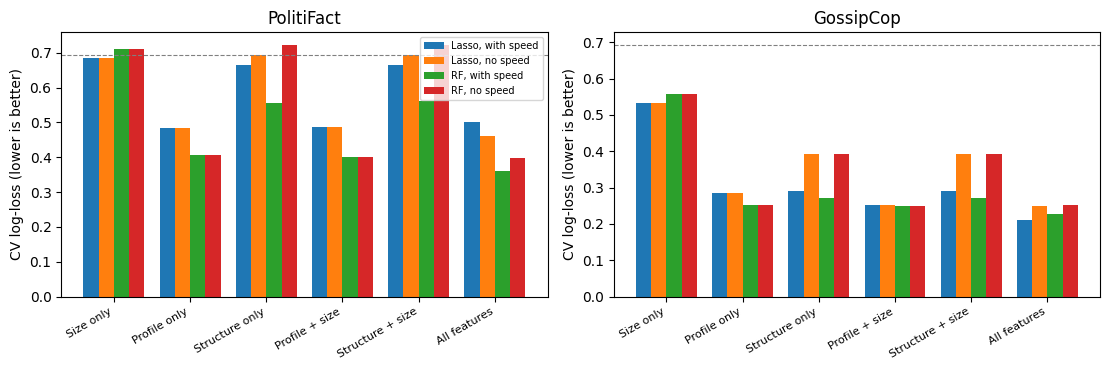

saved figures/rf_group_importance.pdf


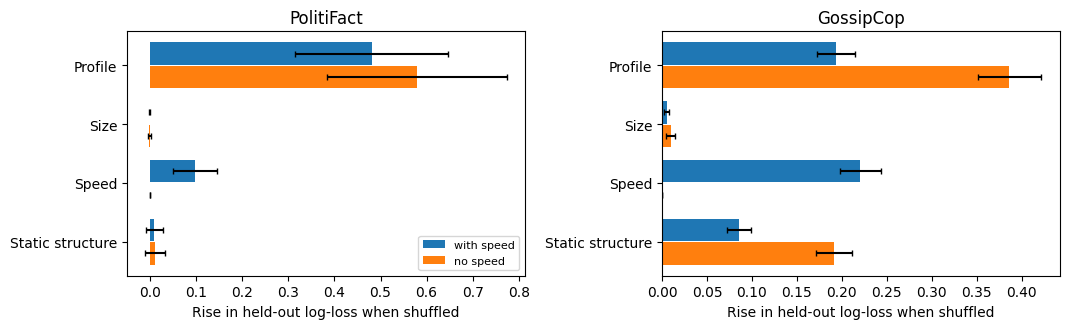


PACKAGING REPORT ASSETS


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Export complete!
Tables: report_assets/tables/
Figures: report_assets/figures/
Download: report_assets.zip


In [96]:

# ============================================================
# FINAL EXPORT: ADVISOR MEETING + MIDTERM REPORT
# Uses existing results; does not rerun regressions or RF models
# ============================================================

DATA = {
    "PolitiFact": {
        "df": pol_all,
        "sel": pol_sel,
        "res": pol_res,
        "res_ns": pol_res_no_speed,
        "rf": pol_rf,
        "rf_ns": pol_rf_no_speed,
        "penalty": "Lasso",
    },

    "GossipCop": {
        "df": gos_all,
        "sel": gos_sel,
        "res": gos_res,
        "res_ns": gos_res_no_speed,
        "rf": gos_rf,
        "rf_ns": gos_rf_no_speed,
        "penalty": "Ridge",
    }
}

# 1. Generate and save all tables
print("=" * 60)
print("EXPORTING TABLES")
print("=" * 60)

export_meeting_tables(DATA)

# 2. Generate and save figures
print("\n" + "=" * 60)
print("EXPORTING FIGURES")
print("=" * 60)

make_meeting_figures(DATA)

# 3. Package everything into one ZIP
print("\n" + "=" * 60)
print("PACKAGING REPORT ASSETS")
print("=" * 60)

zip_assets(download=True)

print("\nExport complete!")
print("Tables: report_assets/tables/")
print("Figures: report_assets/figures/")
print("Download: report_assets.zip")
